# **Clothing Image Classification**

Three independent CNNs and a multi-task CNN are evaluated using Fashion Product Images (Small). Pattern labels are inferred from product names, with optional manual corrections.


## **Setup**


In [ ]:
# Installs the packages needed for image processing, model training, plotting, and evaluation.
# Colab may already provide PyTorch, but this cell ensures the listed dependencies are available.

!pip -q install kagglehub pandas numpy pillow scikit-learn matplotlib torch torchvision

In [ ]:
# Sets up libraries and random seeds.

import argparse, json, random, re, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
SEED = 42
COLORS = ['black', 'white', 'red', 'blue', 'green']
PATTERNS = ['plain', 'striped', 'checked', 'floral']
PATTERN_RE = {'striped': '\\b(stripe|stripes|striped)\\b', 'checked': '\\b(check|checks|checked|checkered|plaid|gingham)\\b', 'floral': '\\b(floral|flower|flowers|flowered)\\b', 'plain': '\\b(plain|solid)\\b'}
print('GPU available:', torch.cuda.is_available())


GPU available: True


## **Data Preparation**

Finds the Kaggle metadata and image files; keeps selected garment categories and colours; extracts explicit pattern keywords; verifies and de-duplicates image files; optionally applies a `pattern_review.csv`; then saves the train/validation/test partitions and label-audit figures.

The split routine checks class coverage and may try multiple seeds. These are the teammate’s original selection rules, not a new procedure.

In [ ]:
# Prepares and splits the clothing dataset.

# Set seeds so repeated experiments start from a consistent state.
def seed_all():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
MIN_CATEGORY = 65
MAX_PER_CATEGORY = 300
MIN_PATTERN = 25
MIN_EVAL_PER_PATTERN = 4

# Filter product metadata, identify labels, check images, and save dataset splits.
def prepare(root, out, max_samples=3000):
    root = Path(root)
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    candidates = list(root.rglob('styles.csv'))
    if not candidates:
        raise FileNotFoundError('styles.csv not found in ' + str(root))
    df = pd.read_csv(candidates[0], on_bad_lines='skip', low_memory=False)
    required = ['id', 'articleType', 'baseColour', 'productDisplayName']
    if any((c not in df for c in required)):
        raise ValueError('Missing metadata fields: ' + str([c for c in required if c not in df]))
    df = df.dropna(subset=required).copy()
    df['color'] = df.baseColour.astype(str).str.lower().str.strip()
    df = df[df.color.isin(COLORS)].copy()
    allowed = {'Tshirts', 'Shirts', 'Jeans', 'Trousers', 'Dresses', 'Tops', 'Kurtas',
               'Sweatshirts', 'Sweaters', 'Jackets', 'Shorts', 'Skirts', 'Blazers',
               'Track Pants', 'Leggings', 'Tunics', 'Coats', 'Cardigans'}
    df = df[df.articleType.isin(allowed)].copy()

    def pattern(name):
        hits = [k for k, regex in PATTERN_RE.items() if re.search(regex, str(name), re.I)]
        return hits[0] if len(hits) == 1 else None
    df['pattern'] = df.productDisplayName.map(pattern)
    df = df.dropna(subset=['pattern']).copy()
    paths = {int(p.stem): p for p in root.rglob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png') and p.stem.isdigit()}
    df['path'] = df.id.map(lambda x: str(paths.get(int(x), '')) if str(x).replace('.0', '').isdigit() else '')
    df = df[df.path != ''].drop_duplicates(subset='id').copy().reset_index(drop=True)
    valid = []
    hashes = []
    for path in df.path:
        try:
            with Image.open(path) as im:
                im.verify()
            with open(path, 'rb') as f:
                digest = hashlib.sha256(f.read()).hexdigest()
            valid.append(True)
            hashes.append(digest)
        except (OSError, ValueError):
            valid.append(False)
            hashes.append(None)
    df = df.loc[valid].copy()
    df['image_sha256'] = [h for h, v in zip(hashes, valid) if v]
    df = df.drop_duplicates(subset='image_sha256').copy()

    # Optional manually reviewed patterns can override the keyword-derived labels.
    review_path = Path('pattern_review.csv')
    reviewed_count = 0
    excluded_count = 0
    if review_path.exists():
        review = pd.read_csv(review_path, dtype={'id': str})
        if not {'id', 'reviewed_pattern'}.issubset(review.columns):
            raise ValueError('pattern_review.csv requires id,reviewed_pattern columns')
        if review.id.duplicated().any():
            raise ValueError('Duplicate IDs in pattern_review.csv')
        mapping = dict(zip(review.id, review.reviewed_pattern.fillna('').astype(str).str.lower().str.strip()))
        df['review'] = df.id.astype(str).map(mapping)
        reviewed_count = int(df.review.notna().sum())
        invalid = set(df.review.dropna()) - set(PATTERNS) - {'exclude'}
        if invalid:
            raise ValueError('Invalid manual pattern review labels: ' + str(invalid))
        excluded_count = int((df.review == 'exclude').sum())
        df = df[df.review != 'exclude'].copy()
        df['pattern'] = df.review.where(df.review.isin(PATTERNS), df.pattern)
        df = df.drop(columns='review')
    df['category'] = df.articleType.astype(str)
    before_counts = df.category.value_counts().to_dict()
    keep = df.category.value_counts()
    keep = set(keep[keep >= MIN_CATEGORY].index)
    df = df[df.category.isin(keep)].copy()
    if df.empty:
        raise ValueError('No category meets MIN_CATEGORY. Lower threshold after inspecting the dataset.')
    parts = []
    for category, part in df.groupby('category'):
        rare = part[part.pattern == 'floral']
        if len(rare) > MAX_PER_CATEGORY:
            rare = rare.sample(MAX_PER_CATEGORY, random_state=SEED)
        slots = MAX_PER_CATEGORY - len(rare)
        other = part[part.pattern != 'floral']
        if len(other) > slots:
            other = other.sample(slots, random_state=SEED)
        parts.append(pd.concat([rare, other]))
    df = pd.concat(parts, ignore_index=True)
    if max_samples and len(df) > max_samples:
        rng = np.random.default_rng(SEED)
        selected = []
        for _, part in df.groupby('pattern'):
            selected.extend(part.sample(n=min(len(part), max(MIN_PATTERN, round(max_samples * len(part) / len(df)))), random_state=SEED).index.tolist())
        selected = list(dict.fromkeys(selected))
        if len(selected) > max_samples:
            selected = rng.choice(selected, size=max_samples, replace=False).tolist()
        elif len(selected) < max_samples:
            remaining = df.index.difference(selected)
            selected += rng.choice(remaining, size=min(max_samples - len(selected), len(remaining)), replace=False).tolist()
        df = df.loc[selected].copy()
    for _ in range(3):
        counts = df.category.value_counts()
        df = df[df.category.isin(counts[counts >= MIN_CATEGORY].index)].copy()
    if len(df) < 100:
        raise ValueError('Insufficient filtered examples: ' + str(len(df)))
    pat_counts = df.pattern.value_counts()
    if any((pat_counts.get(p, 0) < MIN_PATTERN for p in PATTERNS)):
        raise ValueError('Pattern classes too small after filtering: ' + str(pat_counts.to_dict()) + '; adjust MIN_PATTERN or selection only after reviewing labels')
    df = df.reset_index(drop=True)

    # Build the 70/15/15 split while checking label coverage in all partitions.
    train = val = test = None
    used_seed = None
    for offset in range(200):
        seed = SEED + offset
        try:
            a, b = train_test_split(df, test_size=0.3, random_state=seed, stratify=df.pattern)
            v, t = train_test_split(b, test_size=0.5, random_state=seed, stratify=b.pattern)
        except ValueError:
            continue
        if all((set(df[k]) == set(part[k]) for k in ('category', 'color', 'pattern') for part in (a, v, t))) and all((part.pattern.value_counts().reindex(PATTERNS, fill_value=0).min() >= MIN_EVAL_PER_PATTERN for part in (v, t))):
            train, val, test = (a.copy(), v.copy(), t.copy())
            used_seed = seed
            break
    if train is None:
        raise ValueError('Cannot create adequate class coverage after 200 seeded stratified attempts. Inspect class counts; do not silently relax the checks.')
    labels = {k: sorted(df[k].unique().tolist()) for k in ['category', 'color', 'pattern']}
    for part in (train, val, test):
        for k in labels:
            part[k + '_id'] = part[k].map({v: i for i, v in enumerate(labels[k])})
    for k in labels:
        df[k + '_id'] = df[k].map({v: i for i, v in enumerate(labels[k])})
    assert not (set(train.image_sha256) & set(val.image_sha256) or set(train.image_sha256) & set(test.image_sha256) or set(val.image_sha256) & set(test.image_sha256))
    coverage = {k: {name: sorted(set(df[k]) - set(part[k])) for name, part in [('train', train), ('val', val), ('test', test)]} for k in labels}
    assert all((not missing for d in coverage.values() for missing in d.values()))
    (out / 'split_coverage.json').write_text(json.dumps(coverage, indent=2))
    df.groupby(['category', 'color', 'pattern']).size().to_csv(out / 'label_combinations.csv')
    for k in labels:
        pd.DataFrame({name: part[k].value_counts().reindex(labels[k], fill_value=0) for name, part in [('train', train), ('val', val), ('test', test)]}).to_csv(out / (k + '_split_counts.csv'))

    # Save samples and an image montage so pattern labels can be visually audited.
    audit = pd.concat([g.sample(min(12, len(g)), random_state=SEED) for _, g in df.groupby('pattern')], ignore_index=True)
    audit[['id', 'productDisplayName', 'category', 'color', 'pattern', 'path']].to_csv(out / 'pattern_audit.csv', index=False)
    fig, axes = plt.subplots(len(PATTERNS), 6, figsize=(15, 2.7 * len(PATTERNS)), squeeze=False)
    for row, pat in enumerate(PATTERNS):
        subset = audit[audit.pattern == pat].head(6)
        for col, ax in enumerate(axes[row]):
            ax.axis('off')
            if col < len(subset):
                item = subset.iloc[col]
                with Image.open(item.path) as im:
                    ax.imshow(im.convert('RGB'))
                ax.set_title(f'{pat} | {item.id}', fontsize=8)
    fig.suptitle('Pattern Label Samples')
    fig.tight_layout()
    fig.savefig(out / 'pattern_audit_montage.png', dpi=110)
    plt.close(fig)
    df[['id', 'productDisplayName', 'category', 'color', 'pattern', 'path']].sample(min(150, len(df)), random_state=SEED).to_csv(out / 'label_audit.csv', index=False)
    for name, part in [('train', train), ('val', val), ('test', test)]:
        part.to_csv(out / (name + '.csv'), index=False)
    (out / 'labels.json').write_text(json.dumps(labels, indent=2))
    summary = {'total': len(df), 'splits': {'train': len(train), 'val': len(val), 'test': len(test)}, 'counts': {k: df[k].value_counts().to_dict() for k in labels}, 'category_counts_before_filter': before_counts, 'min_category': MIN_CATEGORY, 'max_per_category': MAX_PER_CATEGORY, 'min_pattern': MIN_PATTERN, 'min_eval_per_pattern': MIN_EVAL_PER_PATTERN, 'weak_pattern_labels': True, 'manual_reviewed_rows': reviewed_count, 'manual_exclusions': excluded_count, 'split_seed': used_seed, 'split_method': 'pattern-stratified-with-all-head-coverage-and-minimum-evaluation-counts', 'manual_audit_required': True}
    (out / 'dataset_summary.json').write_text(json.dumps(summary, indent=2))
    print('Split method:', summary['split_method'], 'seed:', used_seed)
    print(json.dumps(summary, indent=2))
    print('Pattern labels: inferred from product names; manual corrections applied:', reviewed_count)


## **Dataset and Augmentation**

`Clothes` loads one RGB image and its three numerical labels per item. Images are resized to `128 × 128`. Only training images receive small rotations/translations. The `stats` function calculates the channel mean and standard deviation from training images for normalization.

In [ ]:
# Loads images and applies data transformations.

# PyTorch Dataset: returns a transformed image and three encoded targets.
class Clothes(Dataset):

    def __init__(self, csv, train=False, mean=(0.5, 0.5, 0.5), std=(0.25, 0.25, 0.25)):
        self.df = pd.read_csv(csv)
        t = [transforms.Resize((128, 128))]
        if train:
            t.append(transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)))
        t += [transforms.ToTensor(), transforms.Normalize(mean, std)]
        self.t = transforms.Compose(t)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        with Image.open(r.path) as im:
            x = self.t(im.convert('RGB'))
        return (x, torch.tensor([int(r.category_id), int(r.color_id), int(r.pattern_id)]))

# Estimate RGB channel statistics from the unaugmented training dataset.
def stats(csv):
    ds = Clothes(csv, mean=(0, 0, 0), std=(1, 1, 1))
    dl = DataLoader(ds, batch_size=32, num_workers=0)
    sums = torch.zeros(3)
    sq = torch.zeros(3)
    n = 0
    for x, _ in dl:
        sums += x.sum((0, 2, 3))
        sq += (x * x).sum((0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    mean = sums / n
    std = (sq / n - mean ** 2).clamp_min(1e-08).sqrt()
    return (mean.tolist(), std.tolist())


## **CNN Models**

`Backbone` is the shared three-stage CNN feature extractor (32, 64, then 128 channels).

`Single` adds one classification head for a baseline task.

`Multi` reuses one backbone with three separate heads to predict category, colour and pattern together.

In [ ]:
# Defines the CNN architectures.

# Convolutional feature extractor used in both model approaches.
class Backbone(nn.Module):

    def __init__(self):
        super().__init__()
        layers = []
        c = 3
        for out in [32, 64, 128]:
            layers += [nn.Conv2d(c, out, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
            c = out
        layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# Three heads share the same learned image representation.
class Multi(nn.Module):

    def __init__(self, sizes):
        super().__init__()
        self.backbone = Backbone()
        self.heads = nn.ModuleList([nn.Linear(128, n) for n in sizes])

    def forward(self, x):
        z = self.backbone(x)
        return [h(z) for h in self.heads]

# One prediction head for a single-attribute baseline.
class Single(nn.Module):

    def __init__(self, n):
        super().__init__()
        self.backbone = Backbone()
        self.head = nn.Linear(128, n)

    def forward(self, x):
        return self.head(self.backbone(x))


## **Training and Evaluation**

`run` trains each of the three single-task CNNs and the multi-task CNN using Adam and cross-entropy loss. Each epoch records training and validation loss, accuracy, and macro-F1.

It saves the lowest-validation-loss model, reloads that checkpoint, and generates confusion matrices, prediction examples, timing, and a summary CSV.

The reported evaluation here uses the validation split; the test split is prepared but not evaluated in this cell.

In [ ]:
# Trains models and saves validation results.
def run(data, out, epochs=10, batch_size=32, model='all'):
    seed_all()
    data = Path(data)
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    labels = json.loads((data / 'labels.json').read_text())
    sizes = [len(labels[k]) for k in ['category', 'color', 'pattern']]
    mean, std = stats(data / 'train.csv')
    (out / 'normalization.json').write_text(json.dumps({'mean': mean, 'std': std}, indent=2))
    loaders = {k: DataLoader(Clothes(data / (k + '.csv'), train=k == 'train', mean=mean, std=std), batch_size=batch_size, shuffle=k == 'train', num_workers=0) for k in ['train', 'val', 'test']}
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Device', device)
    variants = ['category', 'color', 'pattern', 'multi'] if model == 'all' else [model]


    # Train each independent baseline, followed by the multi-task model.
    for variant in variants:
        idx = ['category', 'color', 'pattern'].index(variant) if variant != 'multi' else None
        net = (Multi(sizes) if idx is None else Single(sizes[idx])).to(device)
        opt = torch.optim.Adam(net.parameters(), lr=0.001)
        criterion = nn.CrossEntropyLoss()
        folder = out / variant
        folder.mkdir(exist_ok=True)
        params = {'variant': variant, 'epochs': epochs, 'batch_size': batch_size, 'lr': 0.001, 'seed': SEED, 'mean': mean, 'std': std, 'sizes': sizes, 'parameters': sum((p.numel() for p in net.parameters())), 'device': str(device)}
        (folder / 'params.json').write_text(json.dumps(params, indent=2))
        best = float('inf')
        history = []
        start = time.perf_counter()
        best_epoch = None


        # Each epoch includes gradient-based training and a validation pass.
        for ep in range(1, epochs + 1):
            rec = {'epoch': ep}
            for split in ['train', 'val']:
                net.train(split == 'train')
                total = 0
                count = 0
                true = [[], [], []]
                pred = [[], [], []]
                for x, y in loaders[split]:
                    x = x.to(device)
                    y = y.to(device)
                    with torch.set_grad_enabled(split == 'train'):
                        logits = net(x) if idx is None else [net(x)]
                        indices = range(3) if idx is None else [idx]
                        loss = sum((criterion(logit, y[:, j]) for logit, j in zip(logits, indices)))
                        if split == 'train':
                            opt.zero_grad()
                            loss.backward()
                            opt.step()
                    total += loss.item() * len(x)
                    count += len(x)
                    for logit, j in zip(logits, indices):
                        true[j].extend(y[:, j].cpu().tolist())
                        pred[j].extend(logit.argmax(1).cpu().tolist())
                rec[split + '_loss'] = total / count
                for j in indices:
                    rec[f"{split}_{['category', 'color', 'pattern'][j]}_accuracy"] = accuracy_score(true[j], pred[j])
                    rec[f"{split}_{['category', 'color', 'pattern'][j]}_macro_f1"] = f1_score(true[j], pred[j], labels=list(range(sizes[j])), average='macro', zero_division=0)
            history.append(rec)
            print(variant, rec)


            # Save weights whenever validation loss reaches a new low.
            if rec['val_loss'] < best:
                best = rec['val_loss']
                best_epoch = ep
                torch.save(net.state_dict(), folder / 'best.pt')
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        plt.figure()
        plt.plot([r['epoch'] for r in history], [r['train_loss'] for r in history], label='train')
        plt.plot([r['epoch'] for r in history], [r['val_loss'] for r in history], label='validation')
        plt.xlabel('Epoch')
        plt.ylabel('Cross-entropy loss (sum for multi)')
        plt.legend()
        plt.tight_layout()
        plt.savefig(folder / 'learning_curve.png')
        plt.close()
        (folder / 'timing.json').write_text(json.dumps({'train_seconds': time.perf_counter() - start}, indent=2))


        # Evaluate the best checkpoint on validation data and save plots/tables.
        net.load_state_dict(torch.load(folder / 'best.pt', map_location=device, weights_only=True))
        net.eval()
        ys = [[], [], []]
        ps = [[], [], []]
        examples = []
        with torch.no_grad():
            for x, y in loaders['val']:
                logits = net(x.to(device)) if idx is None else [net(x.to(device))]
                indices = range(3) if idx is None else [idx]
                for lg, j in zip(logits, indices):
                    ys[j].extend(y[:, j].tolist())
                    ps[j].extend(lg.argmax(1).cpu().tolist())
        results = {'variant': variant, 'best_epoch': best_epoch, 'best_val_loss': best, 'parameters': params['parameters']}
        for j in range(3) if idx is None else [idx]:
            key = ['category', 'color', 'pattern'][j]
            results[key + '_accuracy'] = float(accuracy_score(ys[j], ps[j]))
            results[key + '_macro_f1'] = float(f1_score(ys[j], ps[j], labels=list(range(sizes[j])), average='macro', zero_division=0))
            cm = confusion_matrix(ys[j], ps[j], labels=list(range(sizes[j])))
            pd.DataFrame(cm, index=labels[key], columns=labels[key]).to_csv(folder / f'{key}_confusion_matrix.csv')
            fig, ax = plt.subplots(figsize=(max(6, sizes[j] * 0.5), max(5, sizes[j] * 0.5)))
            ax.imshow(cm, cmap='Blues')
            ax.set_xticks(range(sizes[j]), labels[key], rotation=90)
            ax.set_yticks(range(sizes[j]), labels[key])
            ax.set_xlabel('Predicted')
            ax.set_ylabel('Actual')
            ax.set_title(f'{variant}: {key} validation confusion matrix')
            fig.tight_layout()
            fig.savefig(folder / f'{key}_confusion_matrix.png')
            plt.close(fig)
        (folder / 'validation_results.json').write_text(json.dumps(results, indent=2))
        pred_df = loaders['val'].dataset.df[['id', 'path', 'category', 'color', 'pattern']].copy()
        for j in range(3) if idx is None else [idx]:
            key = ['category', 'color', 'pattern'][j]
            pred_df[key + '_predicted'] = [labels[key][v] for v in ps[j]]
        pred_df.to_csv(folder / 'validation_predictions.csv', index=False)
        if len(pred_df):
            sample = pred_df.head(min(9, len(pred_df)))
            fig, axs = plt.subplots(3, 3, figsize=(11, 11))
            axs = axs.ravel()
            for ax, (_, r) in zip(axs, sample.iterrows()):
                with Image.open(r.path) as im:
                    ax.imshow(im.convert('RGB'))
                target = ' / '.join((str(r[k]) for k in ['category', 'color', 'pattern']))
                pred = ' / '.join((str(r.get(k + '_predicted', '—')) for k in ['category', 'color', 'pattern']))
                ax.set_title('True: ' + target + '\nPred: ' + pred, fontsize=7)
                ax.axis('off')
            for ax in axs[len(sample):]:
                ax.axis('off')
            fig.tight_layout()
            fig.savefig(folder / 'prediction_examples.png', dpi=120)
            plt.close(fig)


    # Combine per-model validation results and training times for comparison.
    records = []


    # Train each independent baseline, followed by the multi-task model.
    for variant in variants:
        r = json.loads((out / variant / 'validation_results.json').read_text())
        r['train_seconds'] = json.loads((out / variant / 'timing.json').read_text())['train_seconds']
        records.append(r)
    pd.DataFrame(records).to_csv(out / 'checkpoint_summary.csv', index=False)
    print('Checkpoint complete: use validation results from history.csv; do not fabricate numbers.')


## Dataset Download

**Fetch the Kaggle dataset**

Downloads *Fashion Product Images (Small)* and prints the local dataset path and any detected `styles.csv` files. The dataset is not included in the notebook.

In [ ]:
# Downloads the clothing image dataset.

import kagglehub
root = Path(kagglehub.dataset_download('paramaggarwal/fashion-product-images-small'))
print('Dataset location:', root)
print('Metadata files:', list(root.rglob('styles.csv'))[:3])


Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
Dataset location: /kaggle/input/fashion-product-images-small
Metadata files: [PosixPath('/kaggle/input/fashion-product-images-small/styles.csv'), PosixPath('/kaggle/input/fashion-product-images-small/myntradataset/styles.csv')]


## **Dataset Summary - Prepare data and inspect sample labels**

Runs the original dataset filtering and split procedure. Prints the resulting counts and displays a montage of images with inferred pattern labels, which can be checked for labelling mistakes.

Split method: pattern-stratified-with-all-head-coverage-and-minimum-evaluation-counts seed: 42
{
  "total": 858,
  "splits": {
    "train": 600,
    "val": 129,
    "test": 129
  },
  "counts": {
    "category": {
      "Shirts": 300,
      "Tshirts": 300,
      "Tops": 94,
      "Sweaters": 91,
      "Kurtas": 73
    },
    "color": {
      "blue": 275,
      "white": 192,
      "black": 163,
      "green": 129,
      "red": 99
    },
    "pattern": {
      "striped": 371,
      "plain": 250,
      "checked": 204,
      "floral": 33
    }
  },
  "category_counts_before_filter": {
    "Shirts": 1409,
    "Tshirts": 438,
    "Tops": 94,
    "Sweaters": 91,
    "Kurtas": 73,
    "Trousers": 52,
    "Shorts": 50,
    "Sweatshirts": 44,
    "Jackets": 42,
    "Dresses": 12,
    "Track Pants": 12,
    "Tunics": 6,
    "Skirts": 6,
    "Leggings": 5,
    "Jeans": 3
  },
  "min_category": 65,
  "max_per_category": 300,
  "min_pattern": 25,
  "min_eval_per_pattern": 4,
  "weak_pattern_labels":

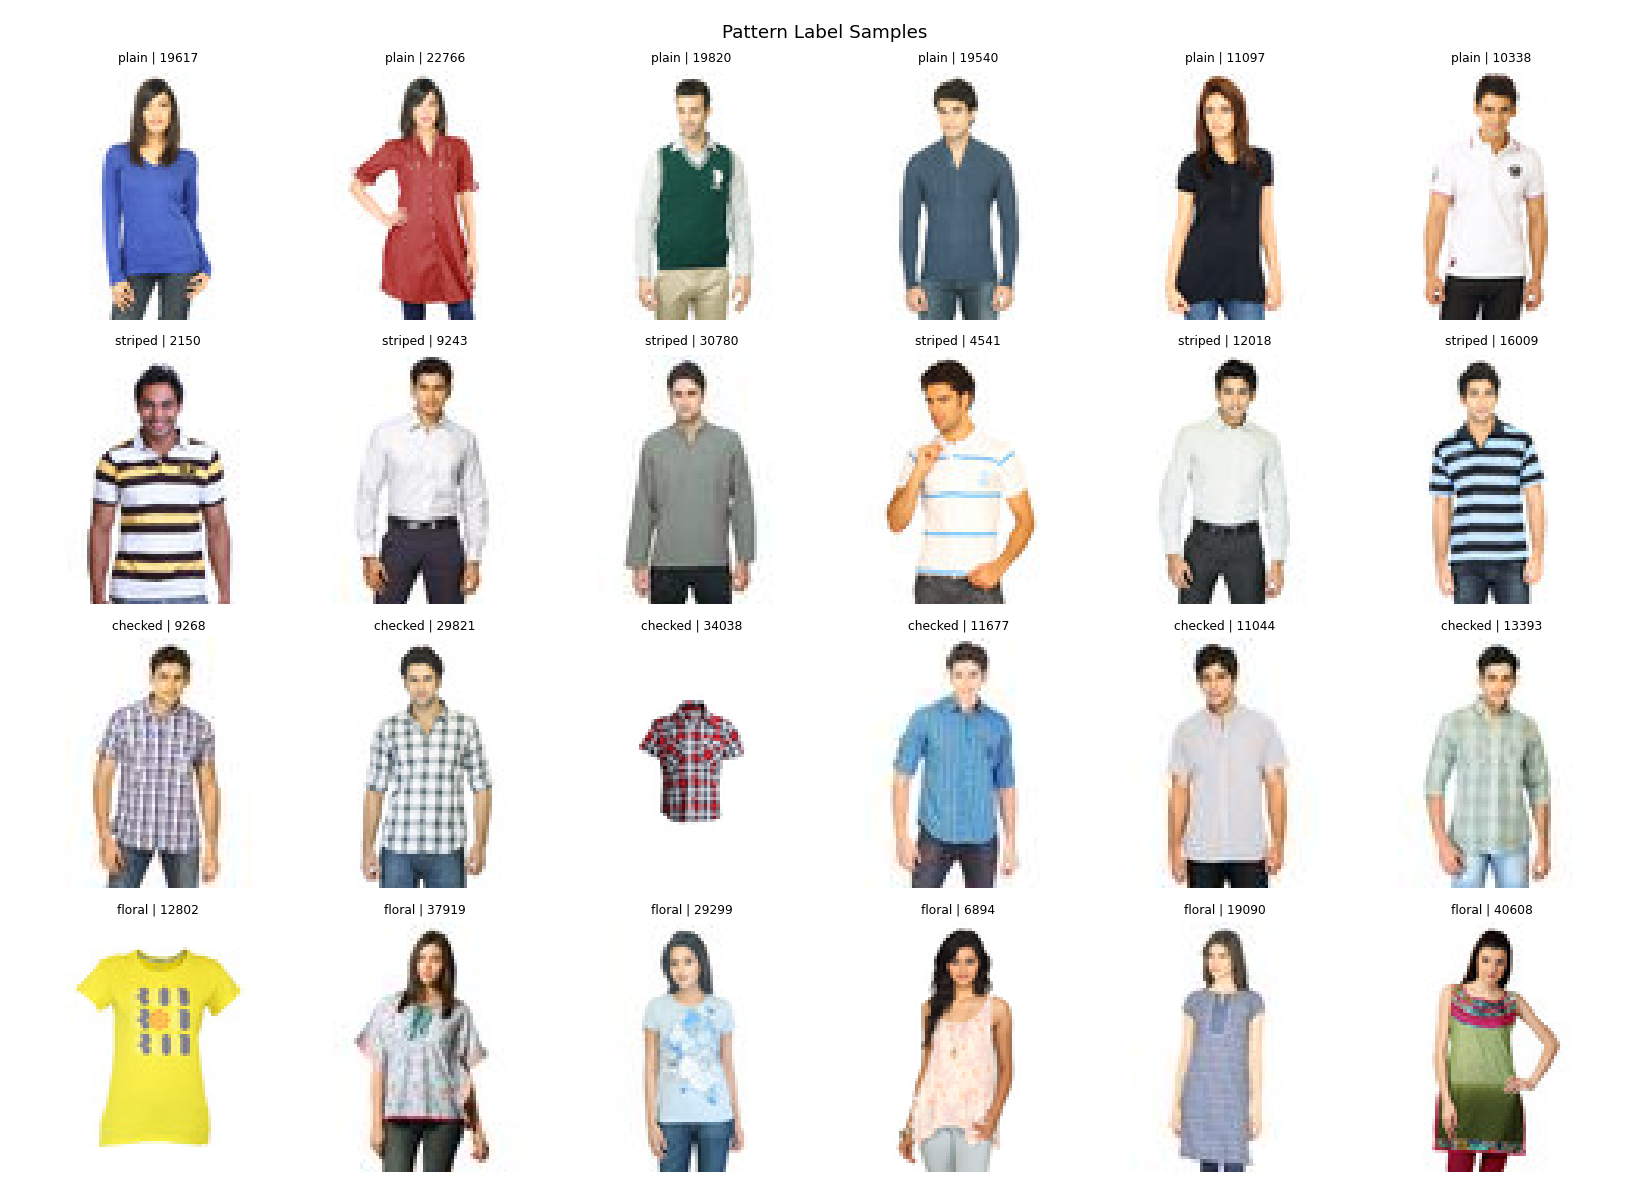

Pattern labels are inferred from product names.


In [ ]:
# Prepares the dataset and displays sample images.

prepare(root, 'prepared', max_samples=3000)
summary = json.loads(Path('prepared/dataset_summary.json').read_text())
print(json.dumps(summary, indent=2))
from IPython.display import display, Image as DisplayImage
display(DisplayImage(filename='prepared/pattern_audit_montage.png'))
print('Pattern labels are inferred from product names.')


## **Model Training - Train 4 Models**

Runs the three independent baselines and shared CNN for 10 epochs with batch size 32. This is a full training cell, not a short smoke test. The original saved run output is kept unchanged.


In [ ]:
# Trains the baseline and multi-task models.

run('prepared', 'runs', epochs=10, batch_size=32, model='all')


Device cuda
category {'epoch': 1, 'train_loss': 1.478757627805074, 'train_category_accuracy': 0.3566666666666667, 'train_category_macro_f1': 0.19809144383256266, 'val_loss': 1.469625245693118, 'val_category_accuracy': 0.3875968992248062, 'val_category_macro_f1': 0.15899371069182391}
category {'epoch': 2, 'train_loss': 1.4495135927200318, 'train_category_accuracy': 0.32666666666666666, 'train_category_macro_f1': 0.1535979449265374, 'val_loss': 1.4243492322374685, 'val_category_accuracy': 0.3488372093023256, 'val_category_macro_f1': 0.11777514792899409}
category {'epoch': 3, 'train_loss': 1.4326188961664836, 'train_category_accuracy': 0.33166666666666667, 'train_category_macro_f1': 0.15627754336615096, 'val_loss': 1.411595135234123, 'val_category_accuracy': 0.4263565891472868, 'val_category_macro_f1': 0.18813825608798115}
category {'epoch': 4, 'train_loss': 1.4288862943649292, 'train_category_accuracy': 0.4033333333333333, 'train_category_macro_f1': 0.18952630557173364, 'val_loss': 1.399

## **Results - Compare the Saved Validation Results**

Displays checkpoint_summary.csv and, for each model, its learning curve and image-level prediction examples. Figures shown below are from the original run and have not been regenerated by this annotation edit.

,variant,best_epoch,best_val_loss,parameters,category_accuracy,category_macro_f1,train_seconds,color_accuracy,color_macro_f1,pattern_accuracy,pattern_macro_f1
0,category,10,1.223095,93893,0.534884,0.253211,25.342119,NaN,NaN,NaN,NaN
1,color,5,0.988552,93893,NaN,NaN,21.500336,0.674419,0.578810,NaN,NaN
2,pattern,8,1.049620,93764,NaN,NaN,21.316741,NaN,NaN,0.558140,0.325256
3,multi,9,3.375039,95054,0.465116,0.217460,22.615968,0.682171,0.634436,0.410853,0.229783


MODEL: category


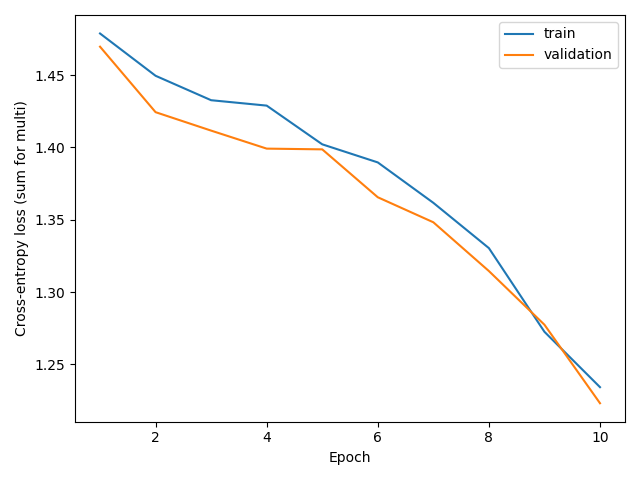

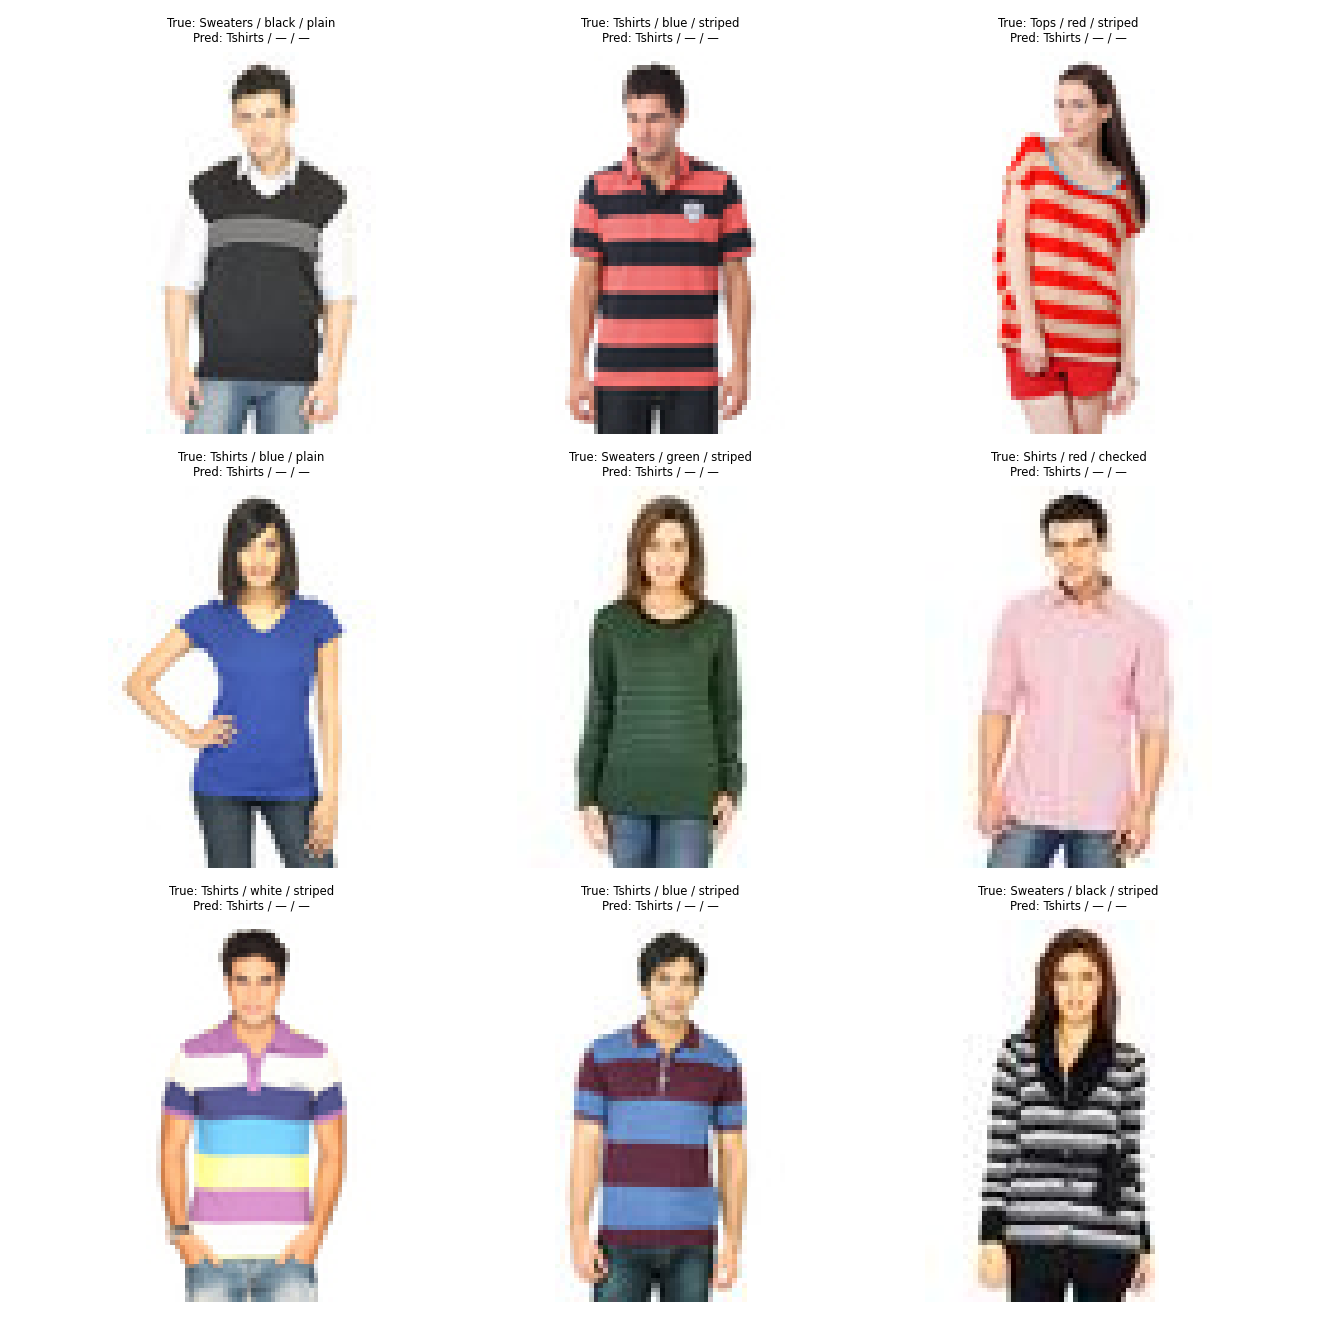

MODEL: color


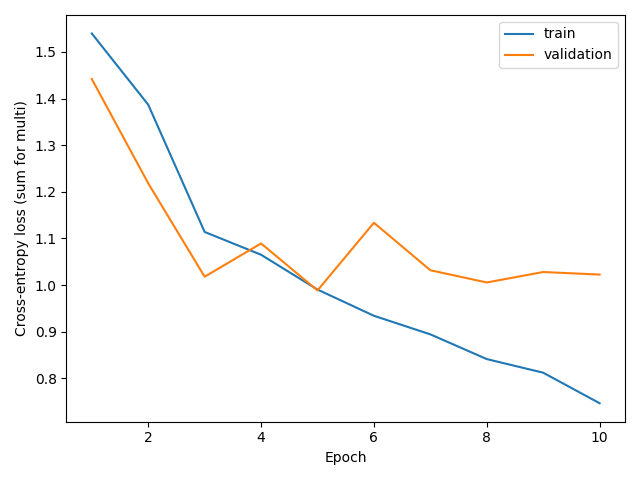

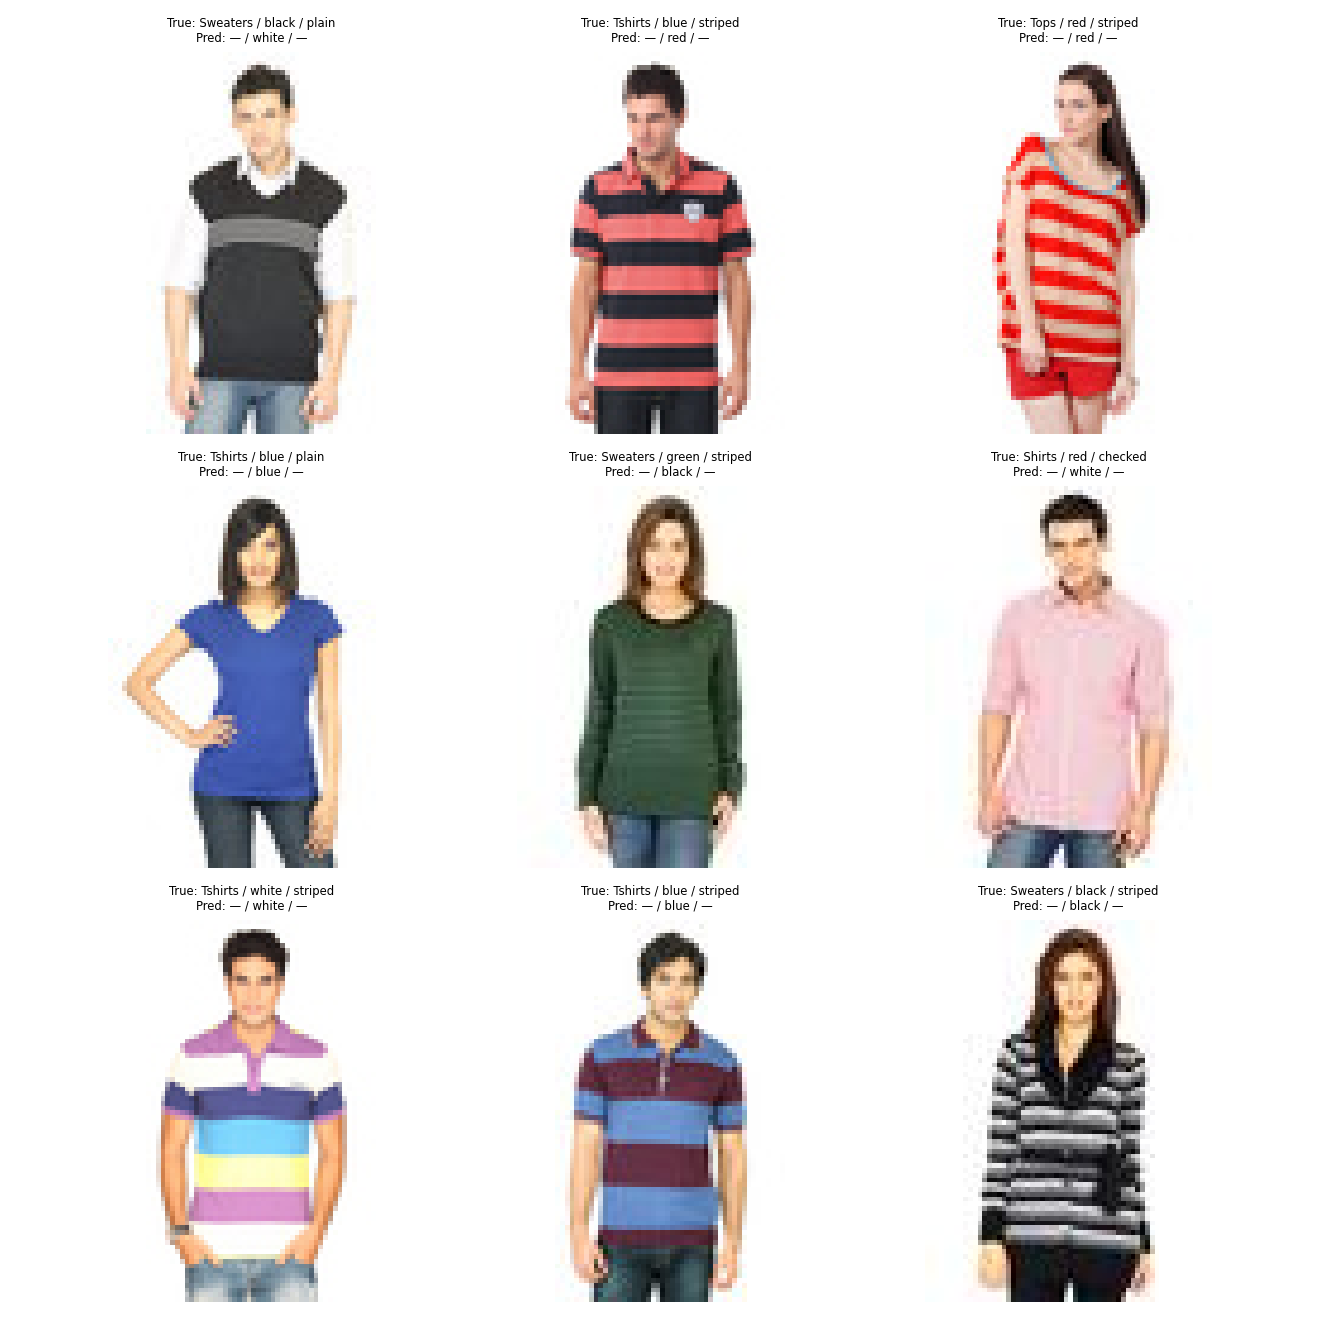

MODEL: pattern


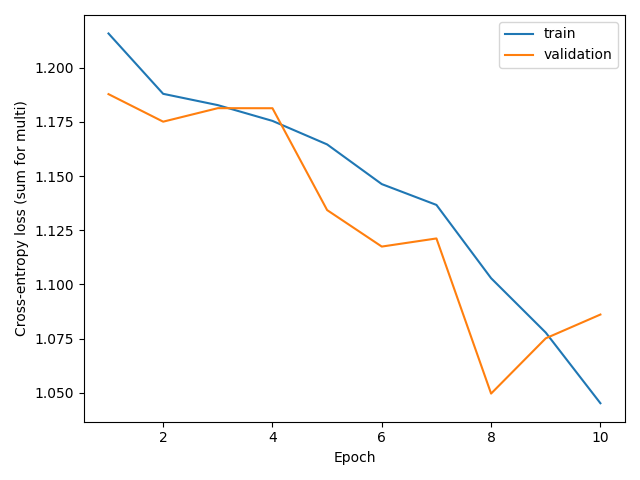

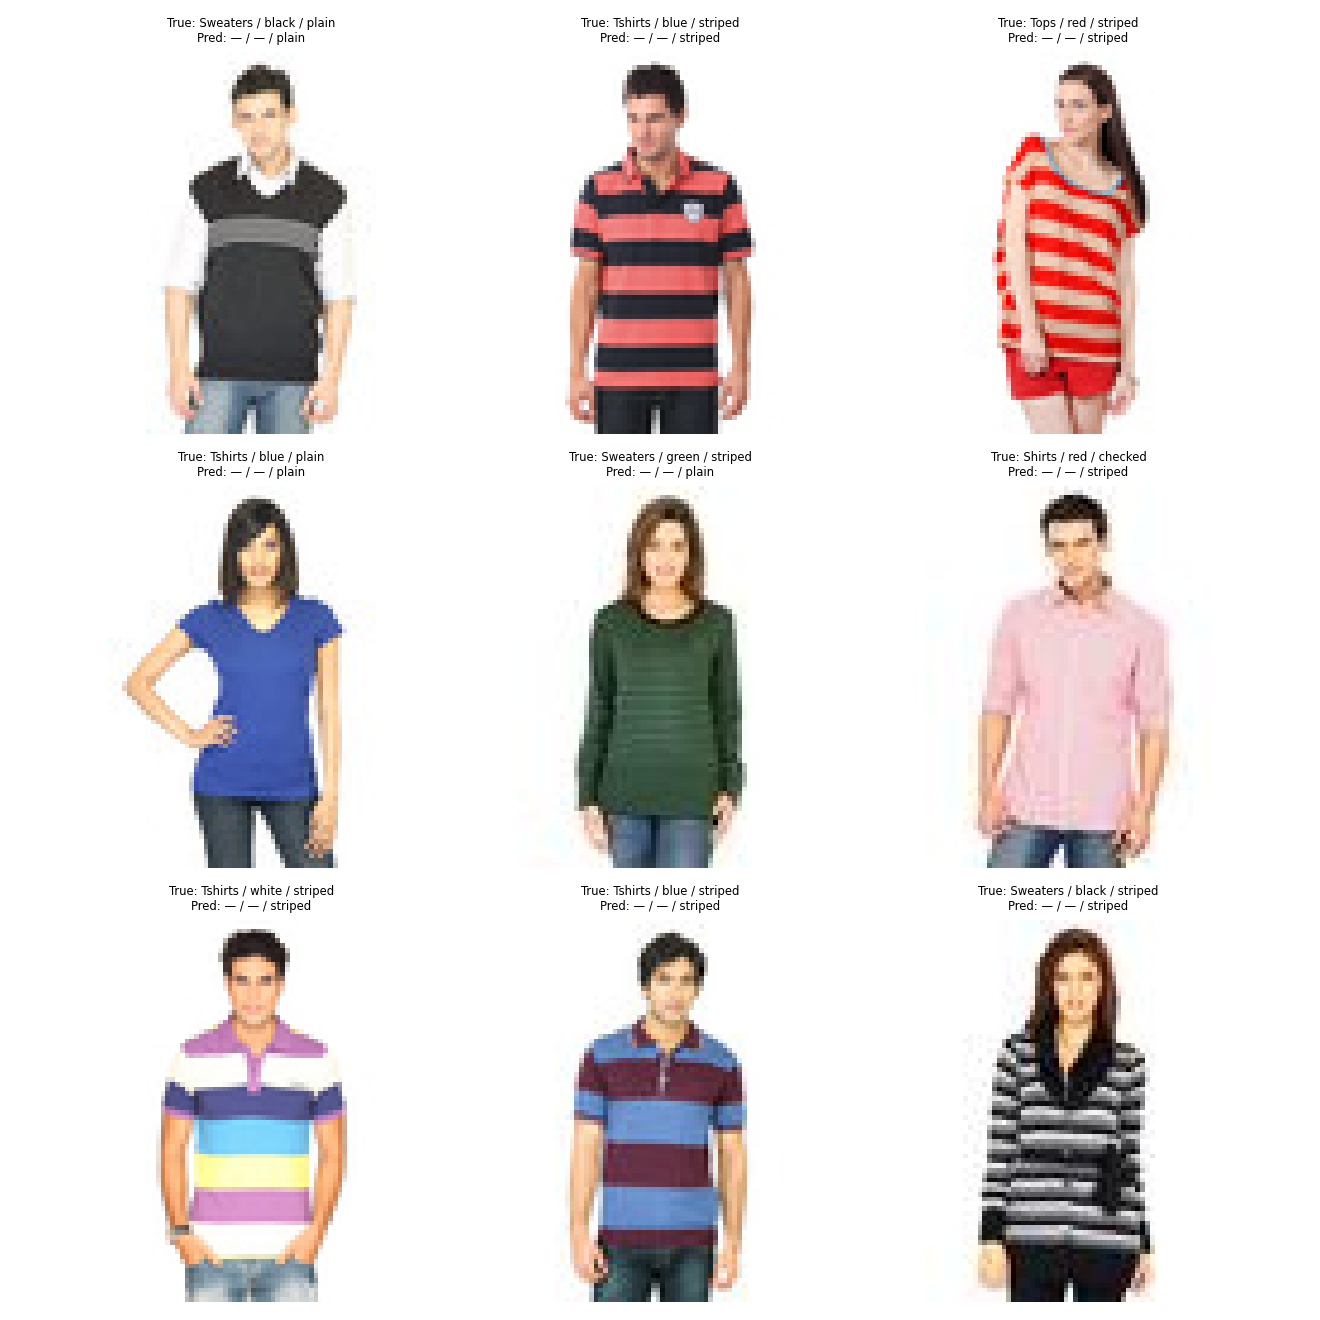

MODEL: multi


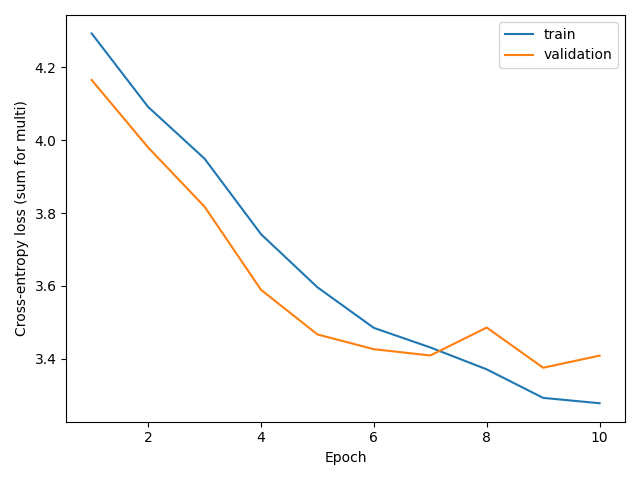

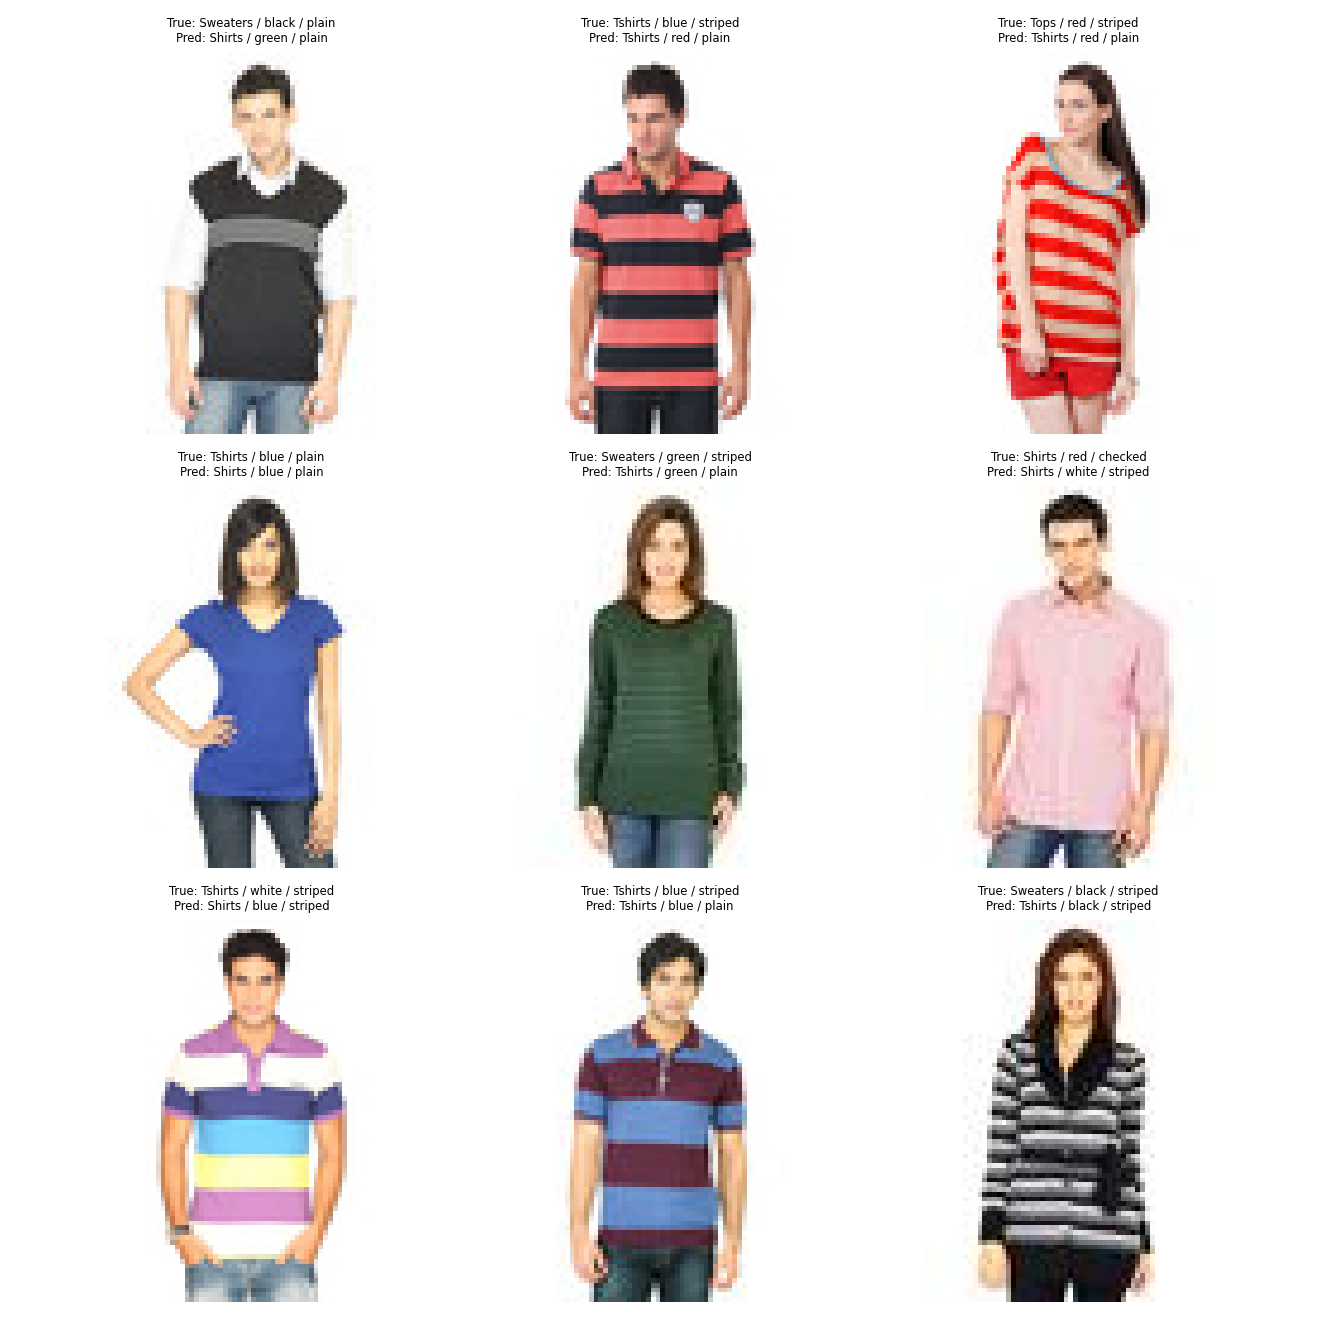

In [ ]:
# Displays validation metrics and plots.

display(pd.read_csv('runs/checkpoint_summary.csv'))
for name in ['category', 'color', 'pattern', 'multi']:
    print('MODEL:', name)
    display(DisplayImage(filename=f'runs/{name}/learning_curve.png'))
    display(DisplayImage(filename=f'runs/{name}/prediction_examples.png'))


## **Export Results**

Packages the runs/ outputs plus prepared dataset information into `milestone2_results.zip` and starts a Colab download. This archive can be used to transfer generated figures, metrics, and model checkpoints.

In [ ]:
# Exports the experiment results.

import shutil
shutil.make_archive('milestone2_results', 'zip', root_dir='.', base_dir='runs')
from zipfile import ZipFile, ZIP_DEFLATED
with ZipFile('milestone2_results.zip', 'a', compression=ZIP_DEFLATED) as z:
    for f in Path('prepared').rglob('*'):
        if f.is_file():
            z.write(f, arcname=str(f))
print('Saved milestone2_results.zip')
from google.colab import files
files.download('milestone2_results.zip')


Saved milestone2_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mount Google Drive to save or copy run artifacts beyond the temporary Colab runtime.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')